# Pilot1 mouse trajectories

Separate recording and movement analysis for the same 15 submitted participants. No classifier, payment gate or memory based exclusion is applied.

## Calculation flow

Matched submissions → Canonical raw run → Eight click to click records → Timestamp and sample checks → Continuous path eligibility → Geometry and acquisition plots.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'static/task/stimuli.js').exists())
for path in [ROOT / 'analysis/mouse_qc', ROOT / 'analysis/drone_task', ROOT / 'analysis']:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
from Pilot1_intake import load_Pilot1
from Pilot1_mouse_analysis import run_mouse_report
%matplotlib inline
BATCH = ROOT / 'analysis/data/Pilot1'
intake = load_Pilot1(BATCH, export=False)
mouse = run_mouse_report(intake)
display(mouse['safe_summary'])

(node:84853) Warning: The 'NO_COLOR' env is ignored due to the 'FORCE_COLOR' env being set.
(Use `node --trace-warnings ...` to show where the warning was created)


,Recording check,Observed
0,Participants,15
1,Complete eight movement summaries,15
2,Readable click records,120
3,Evaluable continuous paths,112
4,Participants with all continuous paths,14
5,Click only records,8
6,Paths leaving the nominal square,3
7,Parsing errors,0


## Feature calculations

$$
L=\sum_{k=1}^{K-1}\lVert\mathbf{x}_{k+1}-\mathbf{x}_k\rVert
\qquad D=\lVert\mathbf{x}_K-\mathbf{x}_1\rVert
$$
$$
T=t_K-t_1 \qquad \mathrm{efficiency}=D/L \qquad \mathrm{speed}=L/(T/1000)
$$

| Input or check | Treatment |
| --- | --- |
| Coordinates | Normalized to the square side |
| Opening click, moves and closing click | Merge chronologically and remove exact consecutive duplicates |
| Invalid timestamps, truncation or count mismatch | Flag in private audit tables |
| Continuous path | At least two move samples and positive move cadence |
| Click only record | Retain duration and endpoints, leave path features missing |
| Off square excursion | Preserve and plot without clipping |

Click to click duration includes waiting and corrections. No smoothing or resampling is applied.

## Acquisition and sampling

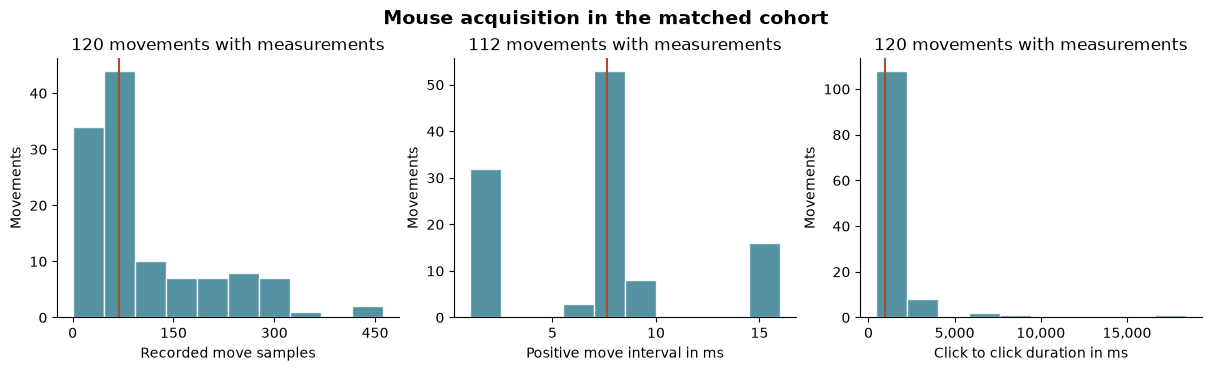

In [2]:
display(mouse['figures']['mouse_acquisition'])

## Recorded paths

Overlay all evaluable continuous paths for each movement. Each subplot retains its full coordinate range, including excursions.

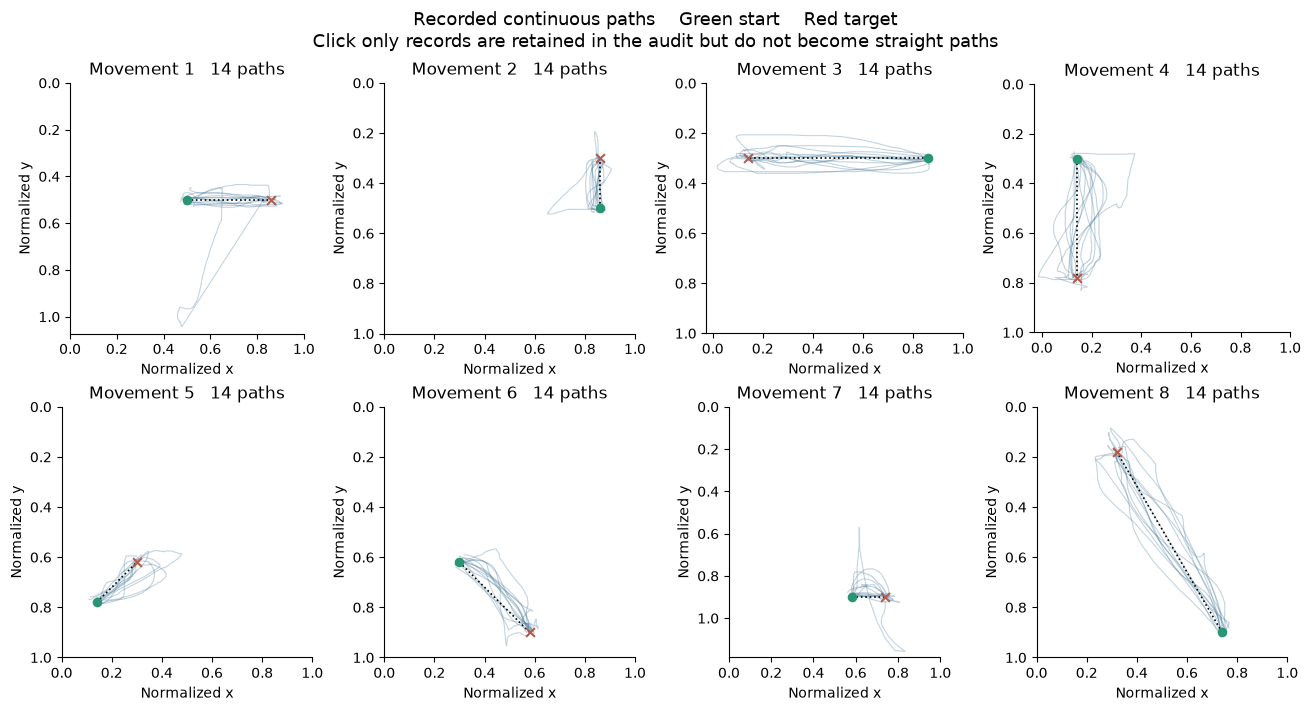

In [3]:
display(mouse['figures']['mouse_paths'])

## Geometry and movement timing

Each thin line is one participant. Movement geometry follows a fixed order, so differences cannot be attributed to geometry alone. Duration uses a logarithmic axis to retain long waits.

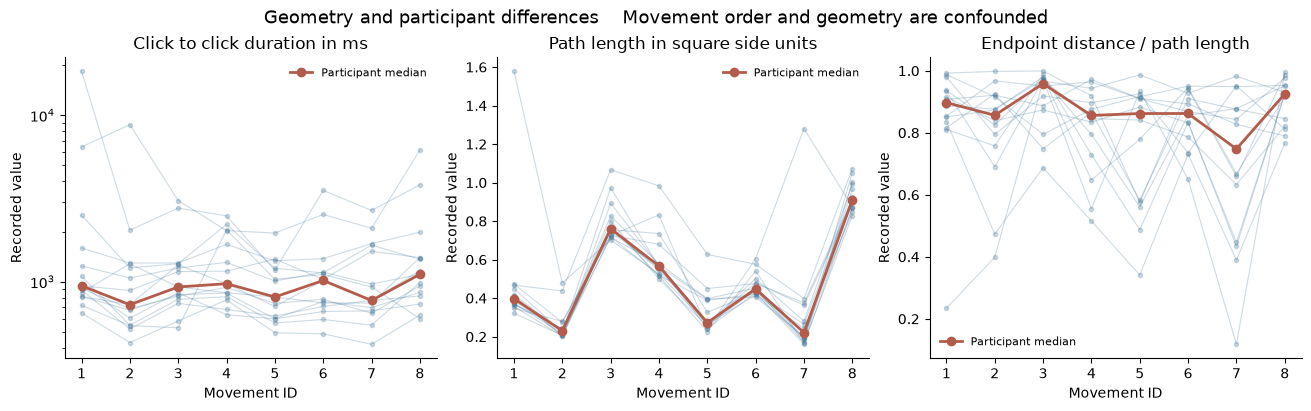

In [4]:
display(mouse['figures']['mouse_geometry'])

## Coverage and interpretation

120 readable click records are retained. Continuous path features are available for 112 movements from 14 people. One participant has eight click only records. These are recording limitations, not evidence of inauthenticity.

Private tables and PNGs are exported to `analysis/data/Pilot1/derived/mouse_qc`. [Task learning, memory and response timing](../drone_task/Pilot1_analysis.ipynb) remain in the main report.